###Project: Exploratory analysis of internship application records

###Tools: Python, pandas, Matplotlib, Seaborn

###Dataset: internship_applications.csv

###Author: Tanu shree Tandon (25LBBC3016)
        Shrashti Shukla (25LBBC3034)      

###1. Imports and dataset loading


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/internship_applications.csv")
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (200, 7)


,Application_ID,Role,Company_Type,Skill_Level,Stage,Response_Time,Last_Stage_Reached
0,1001,Data Analyst,Service-Based,Intermediate,Selected,19,Selected
1,1002,Data Analyst,Product-Based,Intermediate,Rejected,17,Shortlisted
2,1003,Web Developer,MNC,Intermediate,Rejected,4,Test
3,1004,Data Analyst,Startup,Beginner,Rejected,16,Shortlisted
4,1005,Data Analyst,MNC,Beginner,Rejected,3,Test


###2. Initial data checks

In [14]:
print("DATASET OVERVIEW")
print("-" * 35)
print("Dataset shape:", df.shape)
print("\nDataset information:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate application IDs:", df["Application_ID"].duplicated().sum())


DATASET OVERVIEW
-----------------------------------
Dataset shape: (200, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Application_ID      200 non-null    int64
 1   Role                200 non-null    str  
 2   Company_Type        200 non-null    str  
 3   Skill_Level         200 non-null    str  
 4   Stage               200 non-null    str  
 5   Response_Time       200 non-null    int64
 6   Last_Stage_Reached  200 non-null    str  
dtypes: int64(2), str(5)
memory usage: 11.1 KB
None

Missing values:
Application_ID        0
Role                  0
Company_Type          0
Skill_Level           0
Stage                 0
Response_Time         0
Last_Stage_Reached    0
dtype: int64

Duplicate rows: 0
Duplicate application IDs: 0


In [15]:
total_applications = len(df)
selected = (df["Stage"] == "Selected").sum()
selection_rate = selected / total_applications * 100
avg_response = df["Response_Time"].mean()

print("\nINTERNSHIP APPLICATION OVERVIEW")
print("-" * 35)
print("Total Applications:", total_applications)
print("Selected Applications:", selected)
print("Overall Selection Rate:", round(selection_rate, 2), "%")
print("Average Response Time:", round(avg_response, 2), "days")


INTERNSHIP APPLICATION OVERVIEW
-----------------------------------
Total Applications: 200
Selected Applications: 18
Overall Selection Rate: 9.0 %
Average Response Time: 9.12 days


These checks help verify the dataset's size, data types, missing values, and duplicate records. The dashboard provides a quick overview before the detailed analysis begins.

## 3. Recruitment Funnel Analysis

In [16]:
funnel_stages = ["Applied", "Test", "Interview", "Shortlisted", "Selected"]
funnel_counts = [
    len(df),
    df["Last_Stage_Reached"].isin(
        ["Test", "Interview", "Shortlisted", "Selected"]
    ).sum(),
    df["Last_Stage_Reached"].isin(
        ["Interview", "Shortlisted", "Selected"]
    ).sum(),
    df["Last_Stage_Reached"].isin(
        ["Shortlisted", "Selected"]
    ).sum(),
    (df["Stage"] == "Selected").sum()
]
funnel_table = pd.DataFrame({
    "Stage": funnel_stages,
    "Applications Reached": funnel_counts
})
funnel_table["Conversion Rate (%)"] = [
    None
] + [
    round(funnel_counts[i] / funnel_counts[i - 1] * 100, 2)
    for i in range(1, len(funnel_counts))
]
funnel_table["Drop-off"] = [
    None
] + [
    funnel_counts[i - 1] - funnel_counts[i]
    for i in range(1, len(funnel_counts))
]
display(funnel_table)

,Stage,Applications Reached,Conversion Rate (%),Drop-off
0,Applied,200,NaN,NaN
1,Test,175,87.50,25.0
2,Interview,118,67.43,57.0
3,Shortlisted,62,52.54,56.0
4,Selected,18,29.03,44.0


The funnel shows how many applications reached each stage and how many progressed to the next stage. Conversion rates measure progression between consecutive stages, while drop-off counts show the number lost between them. Because an application can appear at multiple stages, funnel counts are not expected to add up to 200.

## 4. Overview of Application Statuses


Total applications: 200


,Number of Applications
Stage,
Applied,10
Test,15
Interview,18
Shortlisted,12
Selected,18
Rejected,127


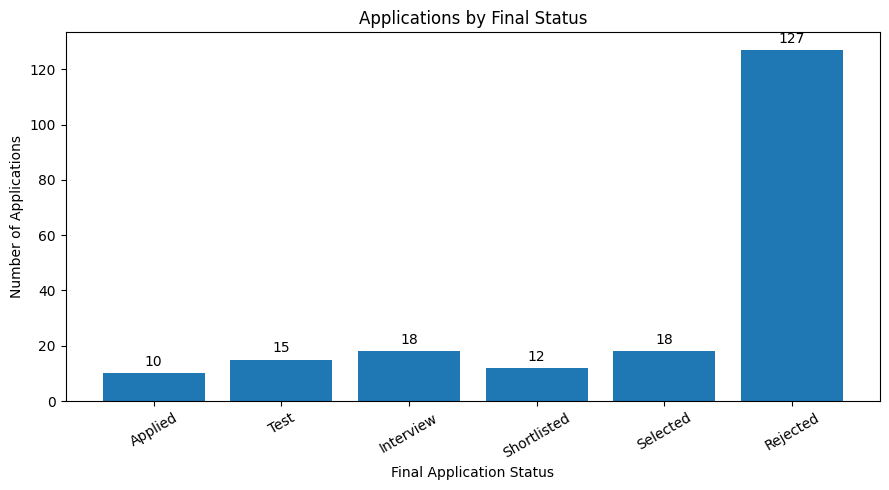

In [17]:
status_order = [
    "Applied", "Test", "Interview",
    "Shortlisted", "Selected", "Rejected"
]
status_counts = df["Stage"].value_counts().reindex(
    status_order,
    fill_value=0
)
print("Total applications:", status_counts.sum())
display(status_counts.rename("Number of Applications").to_frame())
plt.figure(figsize=(9, 5))
bars = plt.bar(status_counts.index, status_counts.values)
plt.bar_label(bars, padding=3)
plt.title("Applications by Final Status")
plt.xlabel("Final Application Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

This chart displays the number of applications in each final recorded status. Unlike the funnel chart, each application appears in exactly one status, so all six bars should add up to 200 when the correct dataset is loaded.

## 5. Selection Outcomes by Role
This section compares the number of applications and the selection rate for each role.

,Applications,Selected,Selection Rate (%)
Role,,,
Business Analyst,17,3,17.65
AI Intern,27,3,11.11
Python Developer,27,3,11.11
Cloud Engineer,32,3,9.38
Web Developer,22,2,9.09
Cybersecurity Analyst,24,2,8.33
Data Analyst,25,1,4.00
Software Engineer,26,1,3.85


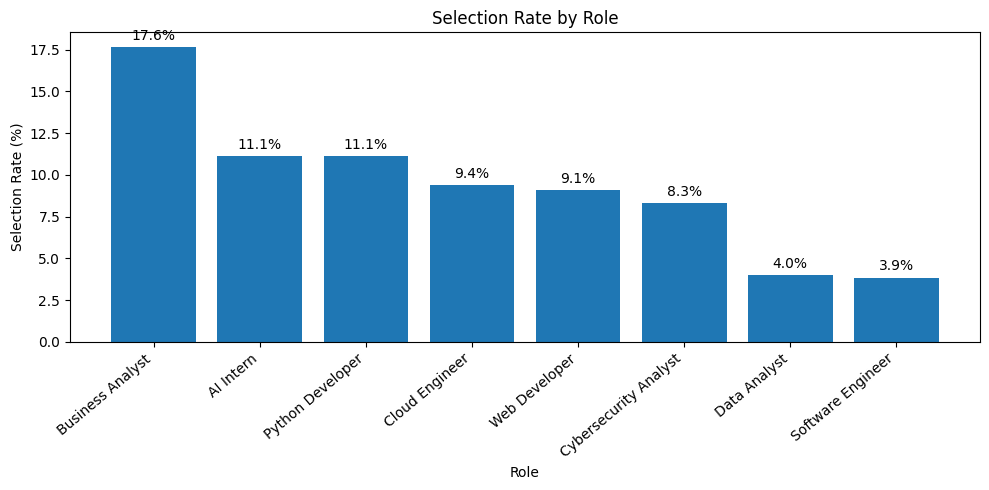

In [18]:
role_analysis = df.groupby("Role").agg(
    Applications=("Application_ID", "count"),
    Selected=("Stage", lambda x: (x == "Selected").sum())
)

role_analysis["Selection Rate (%)"] = (
    role_analysis["Selected"] /
    role_analysis["Applications"] * 100
).round(2)
role_analysis = role_analysis.sort_values(
    "Selection Rate (%)",
    ascending=False
)

display(role_analysis)
plt.figure(figsize=(10, 5))
bars = plt.bar(
    role_analysis.index,
    role_analysis["Selection Rate (%)"]
)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Selection Rate by Role")
plt.xlabel("Role")
plt.ylabel("Selection Rate (%)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

Each role's selection rate is calculated using its own total number of applications. Therefore, the percentages are independent and do not need to add up to 100%.

## 6. Company Type and Response Time
This section compares application counts, selection rates, and response times across company types.

,Applications,Average_Response_Time
Company_Type,,
MNC,67,8.57
Product-Based,40,9.35
Service-Based,39,9.36
Startup,54,9.48


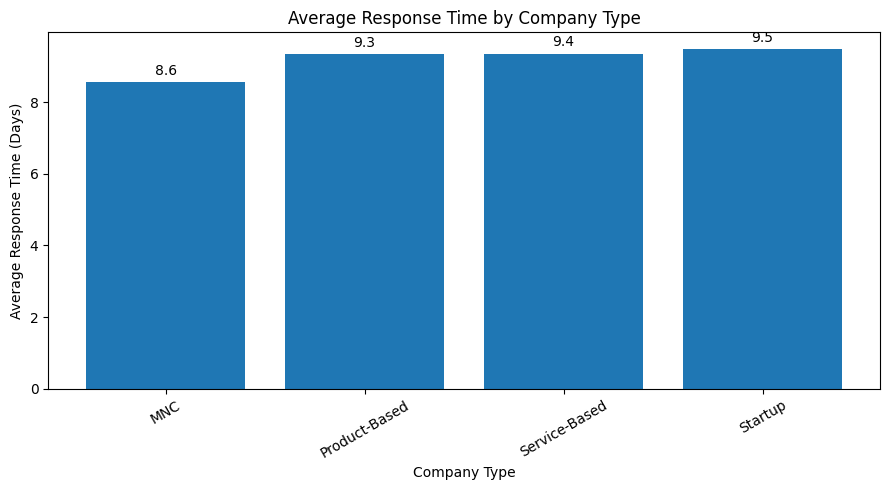

In [19]:
company_response = df.groupby("Company_Type").agg(
    Applications=("Application_ID", "count"),
    Average_Response_Time=("Response_Time", "mean")
)
company_response["Average_Response_Time"] = (
    company_response["Average_Response_Time"].round(2)
)
display(company_response)
plt.figure(figsize=(9, 5))
bars = plt.bar(
    company_response.index,
    company_response["Average_Response_Time"]
)
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.title("Average Response Time by Company Type")
plt.xlabel("Company Type")
plt.ylabel("Average Response Time (Days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

It can highlight differences within the synthetic dataset, but it cannot establish that one company type is generally faster in real recruitment.

##7. Skill Level and Selection Outcomes
This section compares selection rates among beginner, intermediate, and advanced applicants.

,Applications,Selected,Not Selected,Selection Rate (%)
Skill_Level,,,,
Advanced,40,2,38,5.00
Beginner,68,4,64,5.88
Intermediate,92,12,80,13.04


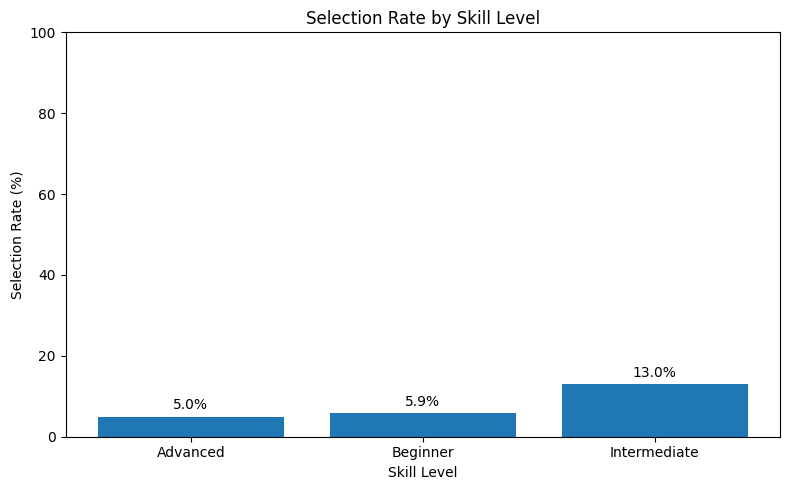

Final Status Counts by Skill Level


Stage,Applied,Interview,Rejected,Selected,Shortlisted,Test
Skill_Level,,,,,,
Advanced,3,2,26,2,3,4
Beginner,2,8,44,4,6,4
Intermediate,5,8,57,12,3,7


In [20]:
skill_analysis = df.groupby("Skill_Level").agg(
    Applications=("Application_ID", "count"),
    Selected=("Stage", lambda x: (x == "Selected").sum())
)

skill_analysis["Not Selected"] = (
    skill_analysis["Applications"] - skill_analysis["Selected"]
)
skill_analysis["Selection Rate (%)"] = (
    skill_analysis["Selected"] /
    skill_analysis["Applications"] * 100
).round(2)
display(skill_analysis)
plt.figure(figsize=(8, 5))
bars = plt.bar(
    skill_analysis.index,
    skill_analysis["Selection Rate (%)"]
)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Selection Rate by Skill Level")
plt.xlabel("Skill Level")
plt.ylabel("Selection Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()
print("Final Status Counts by Skill Level")

skill_status_counts = pd.crosstab(
    df["Skill_Level"],
    df["Stage"]
)

display(skill_status_counts)

All selected applications in this dataset are recorded as Advanced. Beginner and Intermediate applications have no recorded selections. This is a pattern in this dataset and does not establish that skill level alone determines selection.

## 8. Role and Skill-Level Analysis
Here, we compare selection rates for different combinations of roles and skill levels.

,Role,Skill_Level,Applications,Selected,Selection Rate (%)
0,AI Intern,Advanced,7,0,0.00
1,AI Intern,Beginner,10,0,0.00
2,AI Intern,Intermediate,10,3,30.00
3,Business Analyst,Advanced,3,1,33.33
4,Business Analyst,Beginner,7,1,14.29
5,Business Analyst,Intermediate,7,1,14.29
6,Cloud Engineer,Advanced,5,0,0.00
7,Cloud Engineer,Beginner,12,1,8.33
8,Cloud Engineer,Intermediate,15,2,13.33
9,Cybersecurity Analyst,Advanced,6,0,0.00


ROLE AND SKILL COMBINATIONS WITH SELECTIONS


,Role,Skill_Level,Applications,Selected,Selection Rate (%)
3,Business Analyst,Advanced,3,1,33.33
2,AI Intern,Intermediate,10,3,30.00
16,Python Developer,Beginner,9,2,22.22
21,Web Developer,Advanced,6,1,16.67
11,Cybersecurity Analyst,Intermediate,13,2,15.38
4,Business Analyst,Beginner,7,1,14.29
5,Business Analyst,Intermediate,7,1,14.29
8,Cloud Engineer,Intermediate,15,2,13.33
23,Web Developer,Intermediate,10,1,10.00
17,Python Developer,Intermediate,11,1,9.09


Selection rates for these groups may be less reliable.


,Role,Skill_Level,Applications
12,Data Analyst,Advanced,1
3,Business Analyst,Advanced,3
6,Cloud Engineer,Advanced,5
10,Cybersecurity Analyst,Beginner,5
18,Software Engineer,Advanced,5
9,Cybersecurity Analyst,Advanced,6
21,Web Developer,Advanced,6
22,Web Developer,Beginner,6
4,Business Analyst,Beginner,7
0,AI Intern,Advanced,7


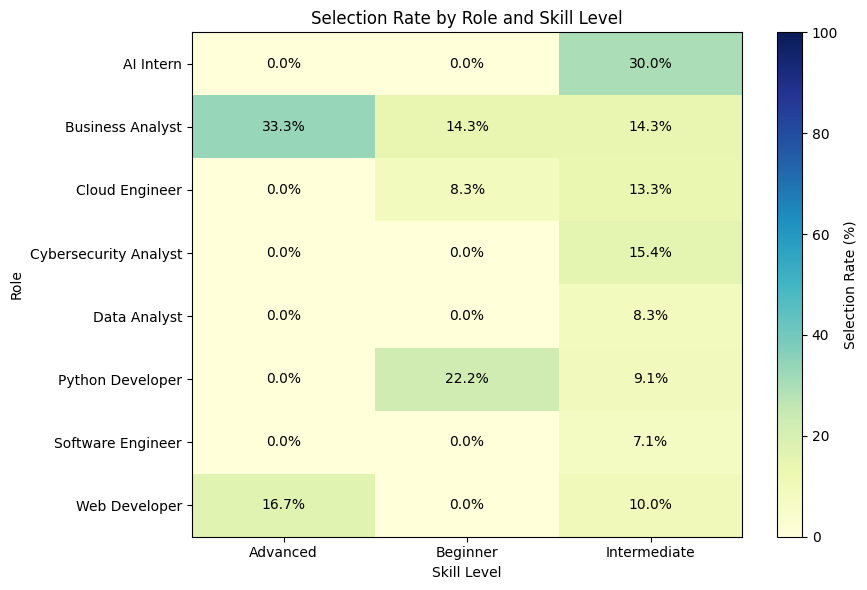

In [21]:
role_skill = df.groupby(
    ["Role", "Skill_Level"]
).agg(
    Applications=("Application_ID", "count"),
    Selected=("Stage", lambda x: (x == "Selected").sum())
).reset_index()

role_skill["Selection Rate (%)"] = (
    role_skill["Selected"] /
    role_skill["Applications"] * 100
).round(2)
display(role_skill)

successful_combinations = role_skill[
    role_skill["Selected"] > 0
].sort_values(
    "Selection Rate (%)",
    ascending=False
)

print("ROLE AND SKILL COMBINATIONS WITH SELECTIONS")
display(successful_combinations)

small_groups = role_skill[
    role_skill["Applications"] < 10
]

if not small_groups.empty:
    print("WARNING: Some role-skill groups have fewer than 10 applications.")
    print("Selection rates for these groups may be less reliable.")

    display(
        small_groups[
            ["Role", "Skill_Level", "Applications"]
        ].sort_values("Applications")
    )
else:
    print("All role-skill groups have at least 10 applications.")
heatmap_data = role_skill.pivot(
    index="Role",
    columns="Skill_Level",
    values="Selection Rate (%)"
)

plt.figure(figsize=(9, 6))
plt.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)
plt.colorbar(label="Selection Rate (%)")
plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)
plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]

        if pd.notna(value):
            plt.text(j, i, f"{value:.1f}%", ha="center", va="center")
plt.title("Selection Rate by Role and Skill Level")
plt.xlabel("Skill Level")
plt.ylabel("Role")
plt.tight_layout()
plt.show()

This section examines selection rates for combinations of job role and skill level. The heatmap makes it easier to compare combinations visually. The small-sample warning identifies groups with fewer than ten applications, where percentages may be less reliable. A high percentage based on very few records should not be treated as strong evidence.

##9. Response Time by Recorded Status
This section compares the average and median response times for applications with different recorded statuses. It does not measure the time spent at each recruitment stage, as the dataset does not contain stage-entry dates.

,Applications,Average_Response_Time
Stage,,
Applied,10,4.00
Interview,18,11.06
Rejected,127,8.46
Selected,18,14.78
Shortlisted,12,11.00
Test,15,7.60


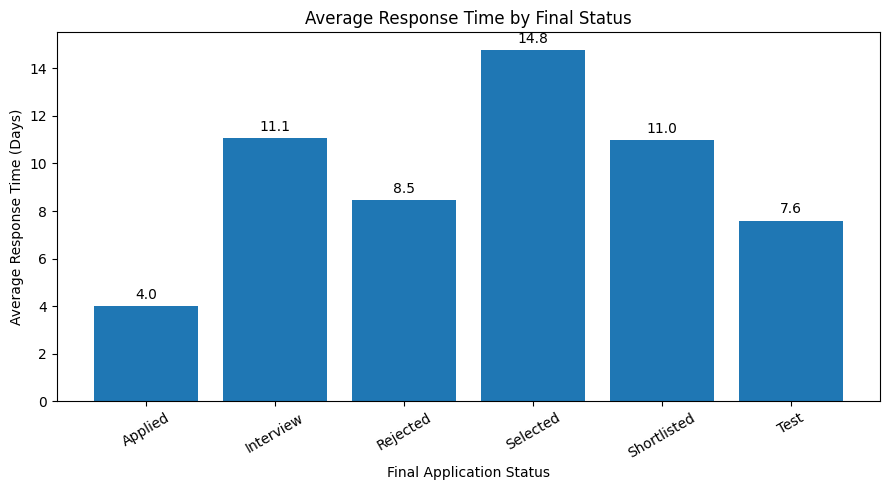

In [22]:
response_by_status = df.groupby("Stage").agg(
    Applications=("Application_ID", "count"),
    Average_Response_Time=("Response_Time", "mean")
)
response_by_status["Average_Response_Time"] = (
    response_by_status["Average_Response_Time"].round(2)
)
display(response_by_status)

plt.figure(figsize=(9, 5))
bars = plt.bar(
    response_by_status.index,
    response_by_status["Average_Response_Time"]
)
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.title("Average Response Time by Final Status")
plt.xlabel("Final Application Status")
plt.ylabel("Average Response Time (Days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

This section compares the average recorded response time for applications in different final statuses. It can help describe patterns in the dataset, but differences in response time do not necessarily explain why an application was selected or rejected.

###10. Application Outcomes by Company Type
This table compares the recorded application statuses across company types.

Stage,Applied,Interview,Rejected,Selected,Shortlisted,Test
Company_Type,,,,,,
MNC,2,5,42,6,4,8
Product-Based,2,4,29,2,1,2
Service-Based,4,5,24,5,1,0
Startup,2,4,32,5,6,5


,Applications,Selected,Selection Rate (%)
Company_Type,,,
MNC,67,6,8.96
Product-Based,40,2,5.00
Service-Based,39,5,12.82
Startup,54,5,9.26


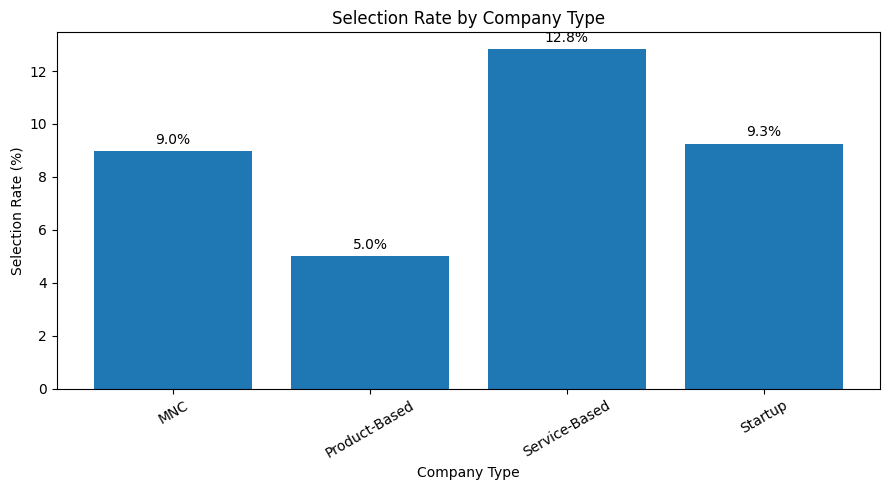

In [23]:
company_outcomes = pd.crosstab(
    df["Company_Type"],
    df["Stage"]
)
display(company_outcomes)

company_selection = df.groupby("Company_Type").agg(
    Applications=("Application_ID", "count"),
    Selected=("Stage", lambda x: (x == "Selected").sum())
)
company_selection["Selection Rate (%)"] = (
    company_selection["Selected"] /
    company_selection["Applications"] * 100
).round(2)

display(company_selection)
plt.figure(figsize=(9, 5))
bars = plt.bar(
    company_selection.index,
    company_selection["Selection Rate (%)"]
)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.title("Selection Rate by Company Type")
plt.xlabel("Company Type")
plt.ylabel("Selection Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 11. Summary of Findings

In [24]:
print("PROJECT SUMMARY")
print("=" * 40)
print("Total applications:", len(df))
print("Selected applications:",
    (df["Stage"] == "Selected").sum()
)
print("Overall selection rate:", round((df["Stage"] == "Selected").mean() * 100, 2),"%")
print("Average response time:",round(df["Response_Time"].mean(), 2),"days")

funnel_dropoffs = funnel_table.dropna(subset=["Drop-off"])
largest_drop = funnel_dropoffs.loc[
    funnel_dropoffs["Drop-off"].idxmax()
]
print("\nLargest absolute drop-off:",int(largest_drop["Drop-off"]),"applications before",largest_drop["Stage"])

conversion_data = funnel_table.dropna(subset=["Conversion Rate (%)"])

if not conversion_data.empty:
    weakest_stage = conversion_data.loc[conversion_data["Conversion Rate (%)"].idxmin()]
    print("Lowest conversion rate:",weakest_stage["Stage"],"-",weakest_stage["Conversion Rate (%)"],"%")
    print("\nRecommendation:")
    if weakest_stage["Stage"] == "Test":
        print("Review test requirements, candidate preparation and assessment instructions.")
    elif weakest_stage["Stage"] == "Interview":
        print(
            "Review interview preparation resources and the criteria used to progress candidates.")
    elif weakest_stage["Stage"] == "Shortlisted":
        print(
            "Review shortlisting criteria and how candidates are evaluated before the final decision.")
    elif weakest_stage["Stage"] == "Selected":
        print(
            "Review final selection criteria and candidate expectations at the last stage.")

print("\nDATA RELIABILITY CHECK")
if not small_groups.empty:
    print(
        "Some role-skill groups contain fewer than 10 applications. "
        "Interpret their selection rates cautiously."
    )
else:
    print("All role-skill groups meet the minimum sample threshold.")

print("\nLIMITATIONS")
print("- The dataset is synthetic and does not represent real recruitment.")
print("- Results describe recorded patterns, not causal relationships.")
print("- Small groups can produce unstable selection rates.")
print("- The analysis describes outcomes; it does not predict selection.")

PROJECT SUMMARY
Total applications: 200
Selected applications: 18
Overall selection rate: 9.0 %
Average response time: 9.12 days

Largest absolute drop-off: 57 applications before Interview
Lowest conversion rate: Selected - 29.03 %

Recommendation:
Review final selection criteria and candidate expectations at the last stage.

DATA RELIABILITY CHECK
Some role-skill groups contain fewer than 10 applications. Interpret their selection rates cautiously.

LIMITATIONS
- The dataset is synthetic and does not represent real recruitment.
- Results describe recorded patterns, not causal relationships.
- Small groups can produce unstable selection rates.
- The analysis describes outcomes; it does not predict selection.
